<a href="https://colab.research.google.com/github/steffanymarcellia046/ProjectETSMachineLearning/blob/main/MODEL_QRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install prophet openpyxl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Library Optuna

In [ ]:
!pip install -q optuna quantile-forest
import optuna
from sklearn.metrics import mean_absolute_error, mean_squared_error

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 920.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 5.2 MB/s eta 0:00:00


ARIMA

In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Siapkan data train dan test (menggunakan data_harian yang sudah ada)
df_arima = data_harian[['ds', 'y']].copy()
df_arima['ds'] = pd.to_datetime(df_arima['ds'])
df_arima.set_index('ds', inplace=True)

split_idx = int(len(df_arima) * 0.8)
train_arima = df_arima.iloc[:split_idx]
test_arima = df_arima.iloc[split_idx:]

# 2. Inisialisasi dan Fitting Model ARIMA
# Sesuaikan order=(p,d,q) sesuai dengan karakteristik datamu
p, d, q = 1, 1, 1
arima_model = ARIMA(train_arima['y'], order=(p, d, q))
arima_fitted = arima_model.fit()

# 3. Prediksi pada Data Test
predictions_arima = arima_fitted.forecast(steps=len(test_arima))

# 4. Evaluasi ARIMA Murni
y_true = test_arima['y'].values
y_pred_arima = predictions_arima.values

mae_arima = mean_absolute_error(y_true, y_pred_arima)
rmse_arima = np.sqrt(mean_squared_error(y_true, y_pred_arima))

print("=== Evaluasi ARIMA Murni ===")
print(f"MAE  : {mae_arima:.2f}")
print(f"RMSE : {rmse_arima:.2f}")

=== Evaluasi ARIMA Murni ===
MAE  : 86.95
RMSE : 104.18


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


QRF + ARIMA

In [ ]:
import optuna
from sklearn.model_selection import TimeSeriesSplit
from quantile_forest import RandomForestQuantileRegressor

# 1. Ambil prediksi ARIMA pada data train untuk menghitung residual train
train_preds_arima = arima_fitted.fittedvalues
train_residual = train_arima['y'] - train_preds_arima

# Buat dataframe untuk pelatihan QRF residual
train_qrf_df = pd.DataFrame({
    'ds': train_arima.index,
    'residual': train_residual
}).dropna()

# Fungsi fitur waktu
def create_time_features(df):
    df = df.copy()
    df['dayofweek'] = df['ds'].dt.dayofweek
    df['month'] = df['ds'].dt.month
    df['day'] = df['ds'].dt.day
    df['dayofyear'] = df['ds'].dt.dayofyear
    return df

train_feat = create_time_features(train_qrf_df)
X_train = train_feat[['dayofweek', 'month', 'day', 'dayofyear']]
y_train_res = train_feat['residual']

# 2. Tuning QRF dengan Optuna
print("Sedang menjalankan Optuna untuk QRF (ARIMA Residual)...")
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 200, step=25),
        'max_depth': trial.suggest_int('max_depth', 5, 25),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 5),
        'random_state': 42
    }

    tscv = TimeSeriesSplit(n_splits=3)
    maes = []

    for tr_idx, val_idx in tscv.split(X_train):
        X_tr, X_val = X_train.iloc[tr_idx], X_train.iloc[val_idx]
        y_tr, y_val = y_train_res.iloc[tr_idx], y_train_res.iloc[val_idx]

        qrf = RandomForestQuantileRegressor(**params)
        qrf.fit(X_tr, y_tr)

        preds = qrf.predict(X_val, quantiles=[0.5])
        if len(preds.shape) > 1:
            preds = preds.flatten()

        maes.append(mean_absolute_error(y_val, preds))

    return np.mean(maes)

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=15)

# Latih ulang QRF dengan parameter terbaik
best_qrf = RandomForestQuantileRegressor(**study.best_params)
best_qrf.fit(X_train, y_train_res)

# 3. Prediksi Residual pada Test Set menggunakan QRF
test_qrf_df = pd.DataFrame({'ds': test_arima.index})
test_feat = create_time_features(test_qrf_df)
X_test = test_feat[['dayofweek', 'month', 'day', 'dayofyear']]

pred_residual_test = best_qrf.predict(X_test, quantiles=[0.5])
if len(pred_residual_test.shape) > 1:
    pred_residual_test = pred_residual_test.flatten()

# 4. Hasil Ensemble = Prediksi ARIMA + Prediksi Residual QRF
y_pred_ensemble_arima = y_pred_arima + pred_residual_test

# 5. Evaluasi Akhir Ensemble ARIMA + QRF
mae_ens_arima = mean_absolute_error(y_true, y_pred_ensemble_arima)
rmse_ens_arima = np.sqrt(mean_squared_error(y_true, y_pred_ensemble_arima))

print("=== Evaluasi Ensemble (ARIMA + QRF) ===")
print(f"MAE  : {mae_ens_arima:.2f}")
print(f"RMSE : {rmse_ens_arima:.2f}")

Sedang menjalankan Optuna untuk QRF (ARIMA Residual)...
=== Evaluasi Ensemble (ARIMA + QRF) ===
MAE  : 71.60
RMSE : 89.99


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Definisi fungsi MAPE dan SMAPE (jika belum didefinisikan sebelumnya)
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / np.maximum(1e-8, np.abs(y_true)))) * 100

def calculate_smape(y_true, y_pred):
    return 100 / len(y_true) * np.sum(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8))

# 2. Fungsi untuk menghasilkan semua metrik evaluasi
def evaluate_all_metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'MSE': mean_squared_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE (%)': calculate_mape(y_true, y_pred),
        'SMAPE (%)': calculate_smape(y_true, y_pred),
        'R2-Score': r2_score(y_true, y_pred)
    }

# 3. Hitung metrik untuk ARIMA Murni dan Ensemble ARIMA + QRF
# (Asumsi y_true, y_pred_arima, dan y_pred_ensemble_arima sudah tersedia)
metrics_arima = evaluate_all_metrics(y_true, y_pred_arima)
metrics_ensemble_arima = evaluate_all_metrics(y_true, y_pred_ensemble_arima)

# 4. Buat tabel perbandingan yang rapi
comparison_table_arima = pd.DataFrame(
    [metrics_arima, metrics_ensemble_arima],
    index=['ARIMA Murni', 'Ensemble (ARIMA + QRF)']
)

print("\n==================================================================")
print("       TABEL PERBANDINGAN EVALUASI MODEL ARIMA & ENSEMBLE         ")
print("==================================================================")
display(comparison_table_arima.round(4))


       TABEL PERBANDINGAN EVALUASI MODEL ARIMA & ENSEMBLE         


,MAE,MSE,RMSE,MAPE (%),SMAPE (%),R2-Score
ARIMA Murni,86.9536,10853.6891,104.1810,15.5158,16.1826,-0.2190
Ensemble (ARIMA + QRF),71.5984,8097.4156,89.9856,12.3863,13.2953,0.0905


Visualisasi Prediksi

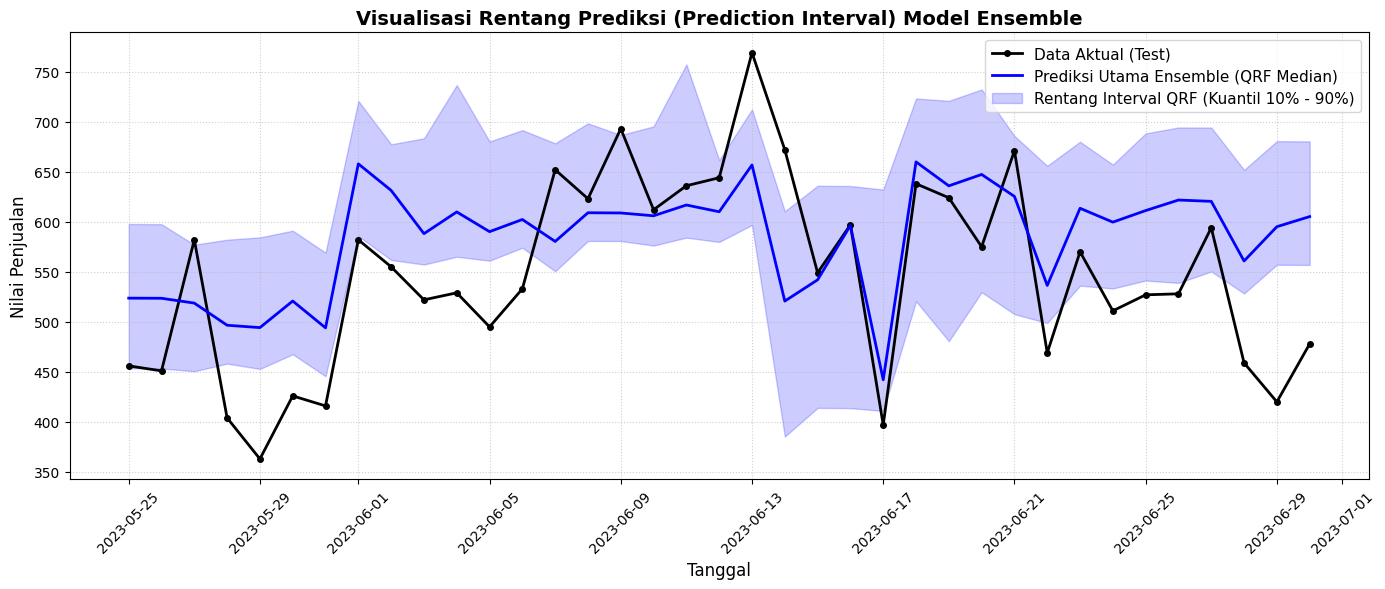

In [ ]:
import matplotlib.pyplot as plt

# 1. Ambil 3 kuantil sekaligus dari QRF:
# 0.1 (Batas Bawah), 0.5 (Median), 0.9 (Batas Atas)
quantiles_target = [0.10, 0.50, 0.90]
pred_res_intervals = best_qrf.predict(X_test, quantiles=quantiles_target)

# Pecah hasil prediksinya per kuantil
res_lower = pred_res_intervals[:, 0]  # Kuantil 0.1
res_median = pred_res_intervals[:, 1] # Kuantil 0.5
res_upper = pred_res_intervals[:, 2]  # Kuantil 0.9

# 2. Tambahkan residual kuantil tersebut ke hasil prediksi Prophet test
y_pred_lower = test_forecast['yhat'].values + res_lower
y_pred_median = test_forecast['yhat'].values + res_median
y_pred_upper = test_forecast['yhat'].values + res_upper

# 3. Visualisasikan dalam bentuk grafik berarsir (Prediction Interval)
plt.figure(figsize=(14, 6))

# Plot data asli (aktual)
plt.plot(pd.to_datetime(test_df['ds']), test_df['y'], label='Data Aktual (Test)', color='black', linewidth=2, marker='o', markersize=4)

# Plot garis tebakan utama (Median Ensemble)
plt.plot(pd.to_datetime(test_df['ds']), y_pred_median, label='Prediksi Utama Ensemble (QRF Median)', color='blue', linewidth=2)

# Plot area arsiran rentang bawah & atas
plt.fill_between(
    pd.to_datetime(test_df['ds']),
    y_pred_lower,
    y_pred_upper,
    color='blue',
    alpha=0.2,
    label='Rentang Interval QRF (Kuantil 10% - 90%)'
)

plt.title("Visualisasi Rentang Prediksi (Prediction Interval) Model Ensemble", fontsize=14, fontweight='bold')
plt.xlabel("Tanggal", fontsize=12)
plt.ylabel("Nilai Penjualan", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# 1. Pastikan variabel prediksi rentang Prophet sudah ada
# (y_pred_lower, y_pred_median, y_pred_upper, dan test_df)

df_audit_prophet = pd.DataFrame({
    'Tanggal': pd.to_datetime(test_df['ds']),
    'Aktual (y)': test_df['y'].values,
    'Prediksi Median': y_pred_median,
    'Batas Bawah (Q10)': y_pred_lower,
    'Batas Atas (Q90)': y_pred_upper
})

# 2. Fungsi penentuan status posisi aktual terhadap rentang QRF
def check_status_prophet(row):
    if row['Aktual (y)'] > row['Batas Atas (Q90)']:
        return 'Di Atas Batas (Anomali Tinggi / Spike)'
    elif row['Aktual (y)'] < row['Batas Bawah (Q10)']:
        return 'Di Bawah Batas (Anomali Rendah / Drop)'
    else:
        return 'Normal (Dalam Rentang)'

df_audit_prophet['Status'] = df_audit_prophet.apply(check_status_prophet, axis=1)

# 3. Filter khusus hari-hari yang berada DI LUAR rentang (Anomali)
df_anomali_prophet = df_audit_prophet[df_audit_prophet['Status'] != 'Normal']

print("\n==================================================================")
print("     AUDIT ANOMALI: ENSEMBLE PROPHET + QRF (DI LUAR RENTANG)       ")
print("==================================================================")
display(df_anomali_prophet.reset_index(drop=True))


     AUDIT ANOMALI: ENSEMBLE PROPHET + QRF (DI LUAR RENTANG)       


,Tanggal,Aktual (y),Prediksi Median,Batas Bawah (Q10),Batas Atas (Q90),Status
0,2023-05-25,456,523.670597,453.661212,597.811613,Normal (Dalam Rentang)
1,2023-05-26,451,523.543498,453.435156,597.585558,Di Bawah Batas (Anomali Rendah / Drop)
2,2023-05-27,582,518.727395,450.626048,577.066363,Di Atas Batas (Anomali Tinggi / Spike)
3,2023-05-28,404,496.606525,458.249124,582.068144,Di Bawah Batas (Anomali Rendah / Drop)
4,2023-05-29,363,494.242718,452.956608,584.390353,Di Bawah Batas (Anomali Rendah / Drop)
5,2023-05-30,426,520.807037,467.591001,591.084609,Di Bawah Batas (Anomali Rendah / Drop)
6,2023-05-31,416,494.008369,445.656856,569.150464,Di Bawah Batas (Anomali Rendah / Drop)
7,2023-06-01,582,657.876956,585.703301,720.766217,Di Bawah Batas (Anomali Rendah / Drop)
8,2023-06-02,555,631.333161,561.840366,677.422537,Di Bawah Batas (Anomali Rendah / Drop)
9,2023-06-03,522,588.127935,557.271270,683.359153,Di Bawah Batas (Anomali Rendah / Drop)


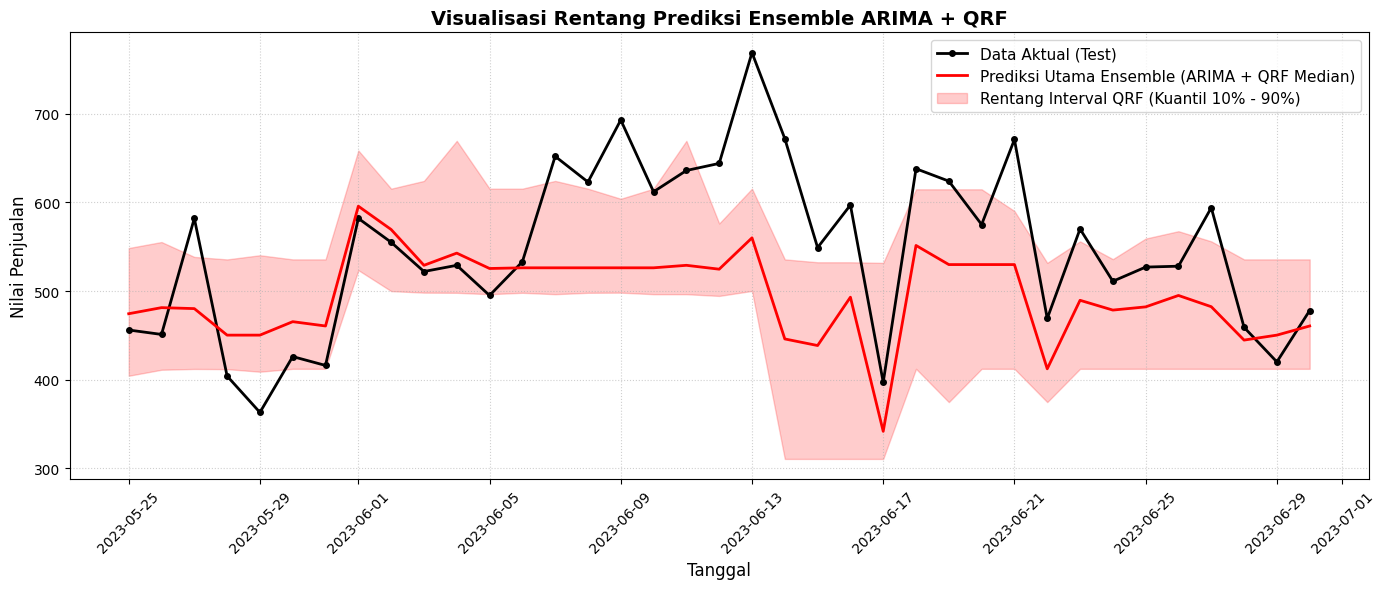

In [ ]:
import matplotlib.pyplot as plt

# 1. Ambil 3 kuantil dari QRF khusus residual ARIMA
quantiles_target = [0.1, 0.5, 0.9]
pred_res_intervals_arima = best_qrf.predict(X_test, quantiles=quantiles_target)

# Pecah per kuantil
res_lower_a = pred_res_intervals_arima[:, 0]
res_median_a = pred_res_intervals_arima[:, 1]
res_upper_a = pred_res_intervals_arima[:, 2]

# 2. Tambahkan ke hasil prediksi ARIMA pada test set
y_pred_lower_arima = y_pred_arima + res_lower_a
y_pred_median_arima = y_pred_arima + res_median_a
y_pred_upper_arima = y_pred_arima + res_upper_a

# 3. Visualisasi Rentang ARIMA + QRF
plt.figure(figsize=(14, 6))
plt.plot(test_arima.index, test_arima['y'], label='Data Aktual (Test)', color='black', linewidth=2, marker='o', markersize=4)
plt.plot(test_arima.index, y_pred_median_arima, label='Prediksi Utama Ensemble (ARIMA + QRF Median)', color='red', linewidth=2)
plt.fill_between(
    test_arima.index,
    y_pred_lower_arima,
    y_pred_upper_arima,
    color='red',
    alpha=0.2,
    label='Rentang Interval QRF (Kuantil 10% - 90%)'
)
plt.title("Visualisasi Rentang Prediksi Ensemble ARIMA + QRF", fontsize=14, fontweight='bold')
plt.xlabel("Tanggal", fontsize=12)
plt.ylabel("Nilai Penjualan", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# 1. Pastikan variabel prediksi rentang ARIMA sudah ada
# (y_pred_lower_arima, y_pred_median_arima, y_pred_upper_arima, dan test_arima)

df_audit_arima = pd.DataFrame({
    'Tanggal': pd.to_datetime(test_arima.index),
    'Aktual (y)': test_arima['y'].values,
    'Prediksi Median': y_pred_median_arima,
    'Batas Bawah (Q10)': y_pred_lower_arima,
    'Batas Atas (Q90)': y_pred_upper_arima
})

# 2. Fungsi penentuan status posisi aktual terhadap rentang QRF
def check_status_arima(row):
    if row['Aktual (y)'] > row['Batas Atas (Q90)']:
        return 'Di Atas Batas (Anomali Tinggi / Spike)'
    elif row['Aktual (y)'] < row['Batas Bawah (Q10)']:
        return 'Di Bawah Batas (Anomali Rendah / Drop)'
    else:
        return 'Normal (Dalam Rentang)'

df_audit_arima['Status'] = df_audit_arima.apply(check_status_arima, axis=1)

# 3. Filter khusus hari-hari yang berada DI LUAR rentang (Anomali)
df_anomali_arima = df_audit_arima[df_audit_arima['Status'] != 'Normal']

print("\n==================================================================")
print("      AUDIT ANOMALI: ENSEMBLE ARIMA + QRF (DI LUAR RENTANG)       ")
print("==================================================================")
display(df_anomali_arima.reset_index(drop=True))


      AUDIT ANOMALI: ENSEMBLE ARIMA + QRF (DI LUAR RENTANG)       


,Tanggal,Aktual (y),Prediksi Median,Batas Bawah (Q10),Batas Atas (Q90),Status
0,2023-05-25,456,474.358615,404.349230,548.499632,Normal (Dalam Rentang)
1,2023-05-26,451,481.234416,411.126075,555.276477,Normal (Dalam Rentang)
2,2023-05-27,582,480.140124,412.038777,538.479091,Di Atas Batas (Anomali Tinggi / Spike)
3,2023-05-28,404,450.193687,411.836287,535.655307,Di Bawah Batas (Anomali Rendah / Drop)
4,2023-05-29,363,450.210242,408.924133,540.357877,Di Bawah Batas (Anomali Rendah / Drop)
5,2023-05-30,426,465.396519,412.180483,535.674091,Normal (Dalam Rentang)
6,2023-05-31,416,460.532297,412.180784,535.674392,Normal (Dalam Rentang)
7,2023-06-01,582,595.718806,523.545151,658.608067,Normal (Dalam Rentang)
8,2023-06-02,555,569.401072,499.908277,615.490448,Normal (Dalam Rentang)
9,2023-06-03,522,529.004954,498.148290,624.236173,Normal (Dalam Rentang)


Evaluasi

In [ ]:
import numpy as np

# 1. Menghitung Coverage Probability (PICP)
# Cek apakah data aktual berada di antara batas bawah (Q10) dan batas atas (Q90)
inside_interval = (y_true >= y_pred_lower) & (y_true <= y_pred_upper)
coverage_probability = np.mean(inside_interval) * 100

# 2. Menghitung Mean Prediction Interval Width (MPIW)
interval_widths = y_pred_upper - y_pred_lower
mean_interval_width = np.mean(interval_widths)

print("==================================================")
print("     EVALUASI KUALITAS INTERVAL QRF (PROPHET)     ")
print("==================================================")
print(f"Prediction Interval Coverage (PICP) : {coverage_probability:.2f}% (Target ideal ~80%)")
print(f"Mean Interval Width (MPIW)          : {mean_interval_width:.2f}")

     EVALUASI KUALITAS INTERVAL QRF (PROPHET)     
Prediction Interval Coverage (PICP) : 37.84% (Target ideal ~80%)
Mean Interval Width (MPIW)          : 148.58


In [ ]:
def pinball_loss(y_true, y_pred, quantile):
    diff = y_true - y_pred
    loss = np.maximum(quantile * diff, (quantile - 1) * diff)
    return np.mean(loss)

# Hitung pinball loss untuk masing-masing kuantil pada test set
# (Pastikan y_pred_lower adalah Q0.1, y_pred_median adalah Q0.5, y_pred_upper adalah Q0.9)
loss_q10 = pinball_loss(y_true, y_pred_lower, quantile=0.1)
loss_q50 = pinball_loss(y_true, y_pred_median, quantile=0.5)
loss_q90 = pinball_loss(y_true, y_pred_upper, quantile=0.9)
average_pinball_loss = np.mean([loss_q10, loss_q50, loss_q90])

print("==================================================")
print("              PINBALL LOSS EVALUATION             ")
print("==================================================")
print(f"Pinball Loss (Kuantil 0.1) : {loss_q10:.4f}")
print(f"Pinball Loss (Kuantil 0.5) : {loss_q50:.4f}")
print(f"Pinball Loss (Kuantil 0.9) : {loss_q90:.4f}")
print(f"Rata-rata Pinball Loss     : {average_pinball_loss:.4f}")

              PINBALL LOSS EVALUATION             
Pinball Loss (Kuantil 0.1) : 24.0989
Pinball Loss (Kuantil 0.5) : 34.7117
Pinball Loss (Kuantil 0.9) : 15.4334
Rata-rata Pinball Loss     : 24.7480


In [ ]:
import numpy as np

# 1. Menghitung Coverage Probability (PICP) untuk ARIMA
# Cek apakah data aktual berada di antara batas bawah (Q10) dan batas atas (Q90) ARIMA
inside_interval_arima = (y_true >= y_pred_lower_arima) & (y_true <= y_pred_upper_arima)
coverage_probability_arima = np.mean(inside_interval_arima) * 100

# 2. Menghitung Mean Prediction Interval Width (MPIW) untuk ARIMA
interval_widths_arima = y_pred_upper_arima - y_pred_lower_arima
mean_interval_width_arima = np.mean(interval_widths_arima)

print("==================================================")
print("     EVALUASI KUALITAS INTERVAL QRF (ARIMA)       ")
print("==================================================")
print(f"Prediction Interval Coverage (PICP) : {coverage_probability_arima:.2f}% (Target ideal ~80%)")
print(f"Mean Interval Width (MPIW)          : {mean_interval_width_arima:.2f}")

     EVALUASI KUALITAS INTERVAL QRF (ARIMA)       
Prediction Interval Coverage (PICP) : 54.05% (Target ideal ~80%)
Mean Interval Width (MPIW)          : 148.58


In [ ]:
def pinball_loss(y_true, y_pred, quantile):
    diff = y_true - y_pred
    loss = np.maximum(quantile * diff, (quantile - 1) * diff)
    return np.mean(loss)

# Hitung pinball loss untuk masing-masing kuantil pada test set ARIMA
loss_q10_arima = pinball_loss(y_true, y_pred_lower_arima, quantile=0.1)
loss_q50_arima = pinball_loss(y_true, y_pred_median_arima, quantile=0.5)
loss_q90_arima = pinball_loss(y_true, y_pred_upper_arima, quantile=0.9)
average_pinball_loss_arima = np.mean([loss_q10_arima, loss_q50_arima, loss_q90_arima])

print("==================================================")
print("          PINBALL LOSS EVALUATION (ARIMA)         ")
print("==================================================")
print(f"Pinball Loss (Kuantil 0.1) : {loss_q10_arima:.4f}")
print(f"Pinball Loss (Kuantil 0.5) : {loss_q50_arima:.4f}")
print(f"Pinball Loss (Kuantil 0.9) : {loss_q90_arima:.4f}")
print(f"Rata-rata Pinball Loss     : {average_pinball_loss_arima:.4f}")

          PINBALL LOSS EVALUATION (ARIMA)         
Pinball Loss (Kuantil 0.1) : 13.1947
Pinball Loss (Kuantil 0.5) : 35.7992
Pinball Loss (Kuantil 0.9) : 24.0098
Rata-rata Pinball Loss     : 24.3346
